<sub>**The Annotated ML Handbook** · Part IV: Visualization</sub>

# Chapter 16: The Seaborn chart gallery

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Mahir-606/annotated-ml-handbook/blob/main/notebooks/part-4-visualization/16-viz-seaborn-gallery.ipynb)

Companion code for the chapter. Every example from the book is here, in order, ready to run. The line-by-line explanations, definitions and discussion are in the book.

Run the setup cell first, then run the cells from top to bottom.

In [1]:
# Repository setup (not part of the book's examples): run this cell first.
import os, sys
from pathlib import Path

# Files the examples create (CSV, models, figures) go into ./outputs next to the notebook.
OUT = Path.cwd() if Path.cwd().name == "outputs" else Path.cwd() / "outputs"
OUT.mkdir(exist_ok=True)
os.chdir(OUT)

# insurance.csv is the practice dataset created in Chapter 11 and reused by later chapters.
# If it is not here yet, copy it from the repository's data/ folder (or download it in Colab).
if not Path("insurance.csv").exists():
    import shutil, urllib.request
    for base in OUT.parents:
        if (base / "data" / "insurance.csv").exists():
            shutil.copy(base / "data" / "insurance.csv", "insurance.csv")
            break
    else:
        try:
            urllib.request.urlretrieve("https://raw.githubusercontent.com/Mahir-606/"
                                       "annotated-ml-handbook/main/data/insurance.csv", "insurance.csv")
        except Exception as e:
            print("Could not fetch insurance.csv; run Chapter 11 first.", e)

# The figure style used in the book.
import matplotlib.pyplot as plt
from cycler import cycler
plt.rcParams.update({
    "figure.figsize": (7.2, 4.0), "figure.dpi": 100,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.28, "grid.linewidth": 0.6,
    "axes.prop_cycle": cycler(color=["#1f4fff", "#e0245e", "#0f9b62", "#ff6a00",
                                     "#7b3ff2", "#0091b3", "#d99a00", "#d42a2a"]),
    "axes.titleweight": "bold", "axes.titlesize": 12.5, "axes.titlelocation": "left",
    "font.size": 10.5, "legend.frameon": False, "image.cmap": "viridis",
})

# Plotly: interactive in Jupyter/Colab; tools/run_all.py stores static PNGs so GitHub can show them.
try:
    import plotly.io as pio
    pio.renderers.default = os.environ.get("PLOTLY_RENDERER") or (
        "colab" if "google.colab" in sys.modules else "notebook_connected")
except ImportError:
    pass

## 16.1 Set-up · *Beginner*

**Imports, theme and data**

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import load_iris
sns.set_theme(style="whitegrid", palette="deep")
ins = pd.read_csv("insurance.csv")
iris = load_iris(as_frame=True).frame
iris["species"] = iris["target"].map(dict(enumerate(load_iris().target_names)))
print(ins.shape, iris.shape)

(1000, 7) (150, 6)


## 16.2 Distribution plots · *Beginner*

### 16.2.1 histplot and kdeplot

**Histogram with KDE, and overlaid KDEs**

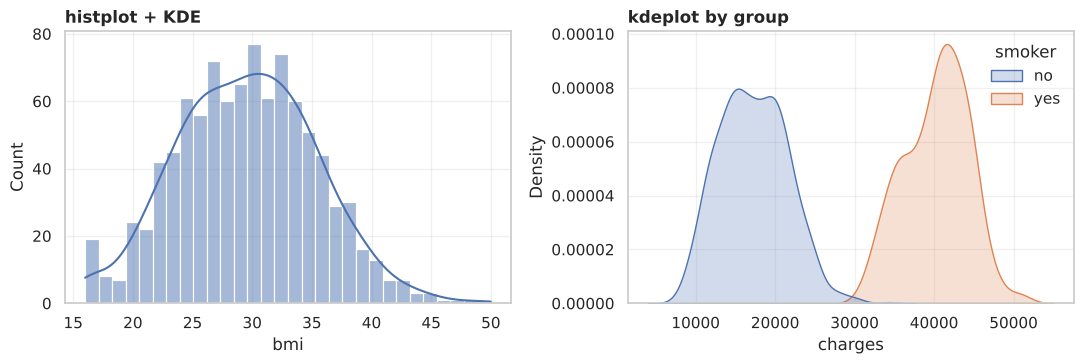

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(data=ins, x="bmi", bins=30, kde=True, ax=axes[0])
axes[0].set_title("histplot + KDE")
sns.kdeplot(data=ins, x="charges", hue="smoker", fill=True, common_norm=False, ax=axes[1])
axes[1].set_title("kdeplot by group")
plt.tight_layout()
plt.show()

### 16.2.2 ecdfplot and rugplot

**ECDF with a rug**

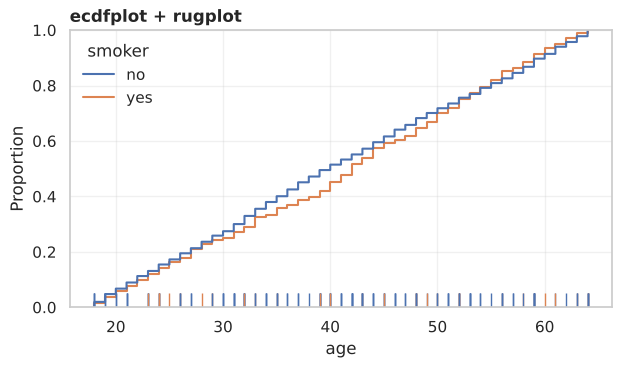

In [4]:
fig, ax = plt.subplots(figsize=(7, 3.6))
sns.ecdfplot(data=ins, x="age", hue="smoker", ax=ax)
sns.rugplot(data=ins.sample(150, random_state=0), x="age", hue="smoker", height=0.05, ax=ax, legend=False)
ax.set_title("ecdfplot + rugplot")
plt.show()

### 16.2.3 displot: small multiples of distributions

**One histogram per region and smoker status**

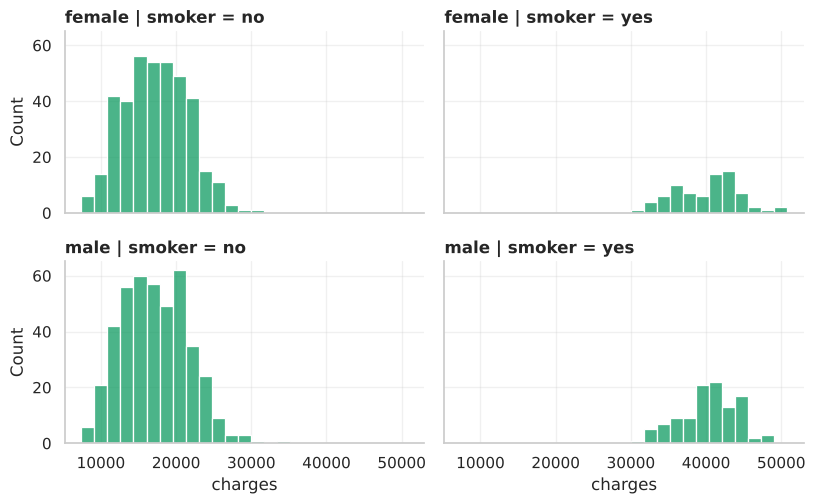

In [5]:
g = sns.displot(data=ins, x="charges", col="smoker", row="sex", bins=25,
                height=2.6, aspect=1.6, color="#0f9b62")
g.set_titles("{row_name} | smoker = {col_name}")
plt.show()

## 16.3 Relationship plots · *Beginner*

### 16.3.1 scatterplot and lineplot

**Scatter with four encodings; line with a confidence band**

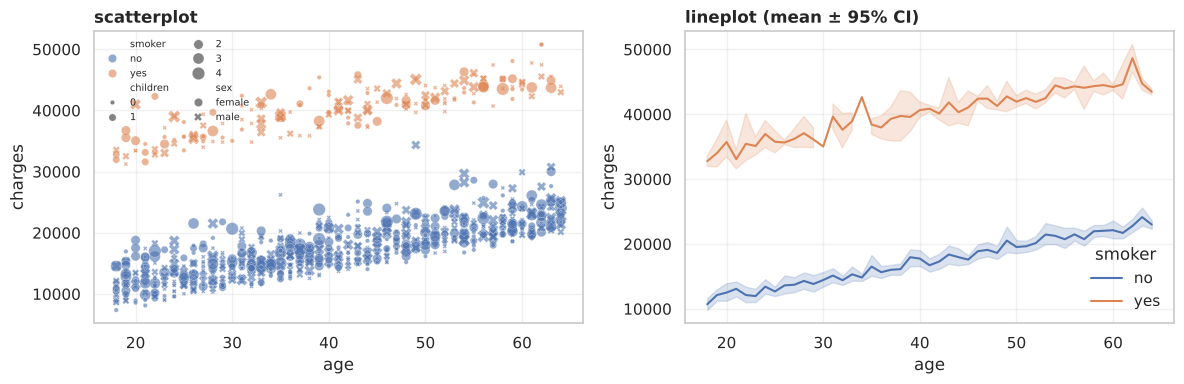

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=ins, x="age", y="charges", hue="smoker", style="sex", size="children",
                sizes=(10, 80), alpha=0.6, ax=axes[0])
axes[0].set_title("scatterplot")
axes[0].legend(fontsize=7, loc="upper left", ncol=2)
sns.lineplot(data=ins, x="age", y="charges", hue="smoker", errorbar=("ci", 95), ax=axes[1])
axes[1].set_title("lineplot (mean ± 95% CI)")
plt.tight_layout()
plt.show()

### 16.3.2 relplot: faceted relationships

**Relationship split by region**

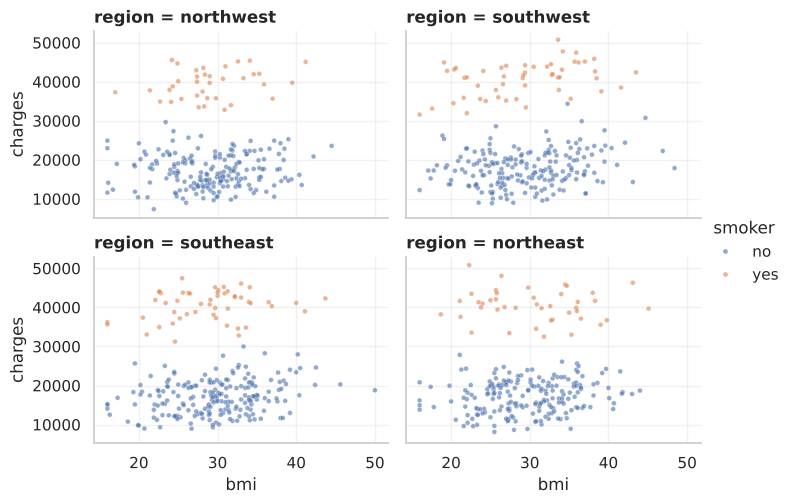

In [7]:
g = sns.relplot(data=ins, x="bmi", y="charges", hue="smoker", col="region", col_wrap=2,
                height=2.6, aspect=1.4, s=12, alpha=0.6)
plt.show()

## 16.4 Regression plots · *Intermediate*

### 16.4.1 regplot, residplot and lmplot

**A fit and its residuals**

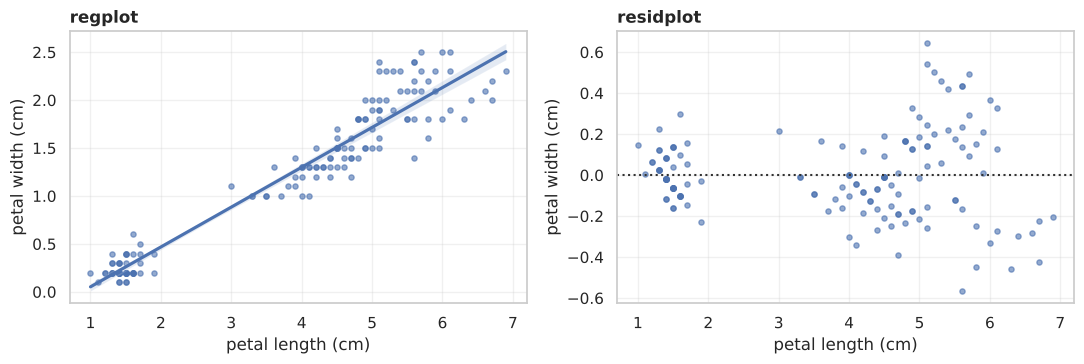

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.regplot(data=iris, x="petal length (cm)", y="petal width (cm)", ax=axes[0],
            scatter_kws={"s": 14, "alpha": 0.6})
axes[0].set_title("regplot")
sns.residplot(data=iris, x="petal length (cm)", y="petal width (cm)", ax=axes[1],
              scatter_kws={"s": 14, "alpha": 0.6})
axes[1].set_title("residplot")
plt.tight_layout()
plt.show()

**lmplot: one regression per group**

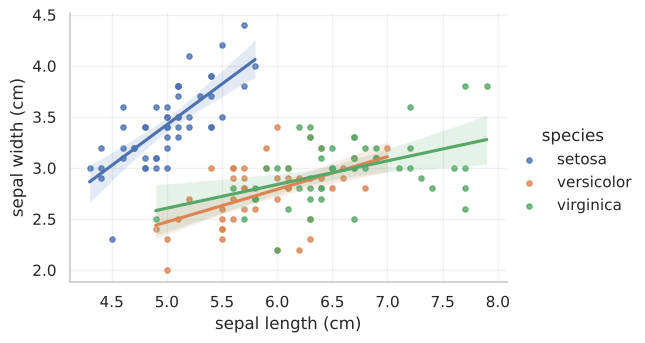

In [9]:
g = sns.lmplot(data=iris, x="sepal length (cm)", y="sepal width (cm)", hue="species",
               height=3.6, aspect=1.5, scatter_kws={"s": 14})
plt.show()

## 16.5 Categorical plots · *Beginner*

### 16.5.1 strip, swarm, box, violin and boxen

**Five ways to show a numeric variable across categories**

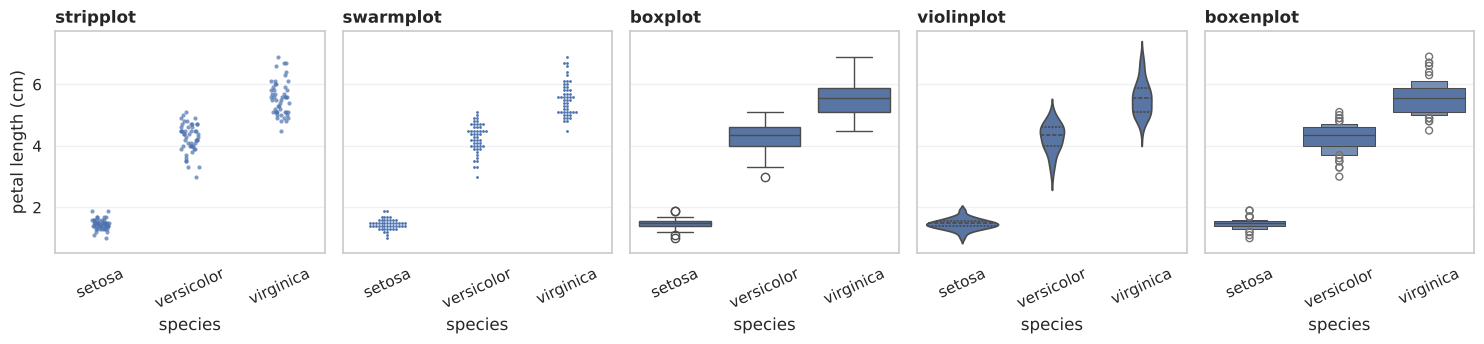

In [10]:
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6), sharey=True)
kw = dict(data=iris, x="species", y="petal length (cm)")
sns.stripplot(**kw, ax=axes[0], size=3, alpha=0.7); axes[0].set_title("stripplot")
sns.swarmplot(**kw, ax=axes[1], size=2); axes[1].set_title("swarmplot")
sns.boxplot(**kw, ax=axes[2]); axes[2].set_title("boxplot")
sns.violinplot(**kw, ax=axes[3], inner="quart"); axes[3].set_title("violinplot")
sns.boxenplot(**kw, ax=axes[4]); axes[4].set_title("boxenplot")
for a in axes: a.tick_params(axis="x", rotation=25)
plt.tight_layout()
plt.show()

### 16.5.2 barplot, pointplot and countplot

**Means, interactions and counts**

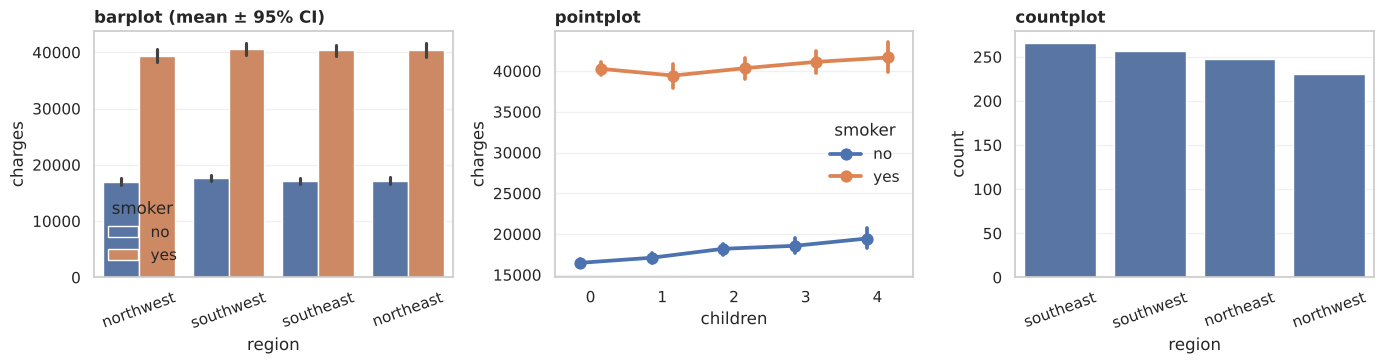

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
sns.barplot(data=ins, x="region", y="charges", hue="smoker", ax=axes[0])
axes[0].set_title("barplot (mean ± 95% CI)"); axes[0].tick_params(axis="x", rotation=20)
sns.pointplot(data=ins, x="children", y="charges", hue="smoker", dodge=0.3, ax=axes[1])
axes[1].set_title("pointplot")
sns.countplot(data=ins, x="region", order=ins["region"].value_counts().index, ax=axes[2])
axes[2].set_title("countplot"); axes[2].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

### 16.5.3 catplot: faceted categorical plots

**Any categorical plot as a grid**

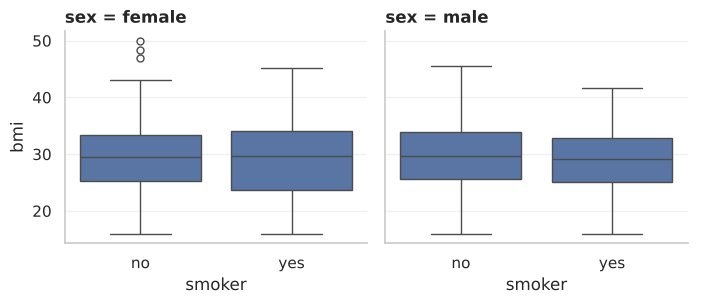

In [12]:
g = sns.catplot(data=ins, x="smoker", y="bmi", col="sex", kind="box",
                height=3.2, aspect=1.1)
plt.show()

## 16.6 Matrix plots · *Intermediate*

### 16.6.1 heatmap and clustermap

**Correlation heatmap**

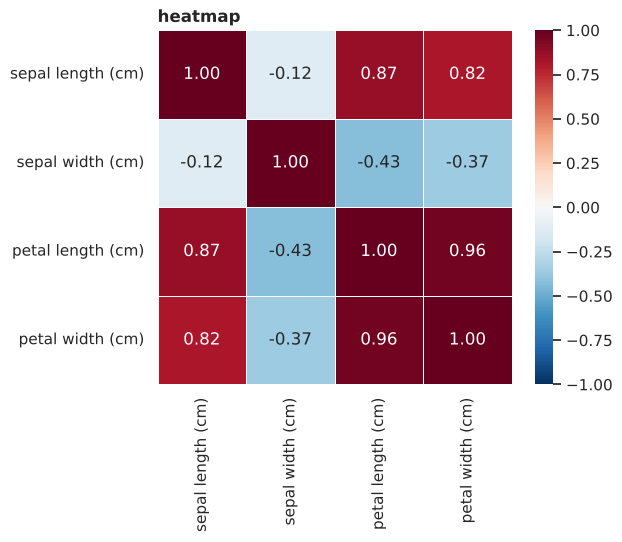

In [13]:
corr = iris.drop(columns=["target", "species"]).corr()
fig, ax = plt.subplots(figsize=(6, 4.6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, center=0,
            square=True, linewidths=0.5, ax=ax)
ax.set_title("heatmap")
plt.show()

**Clustermap groups similar rows and columns**

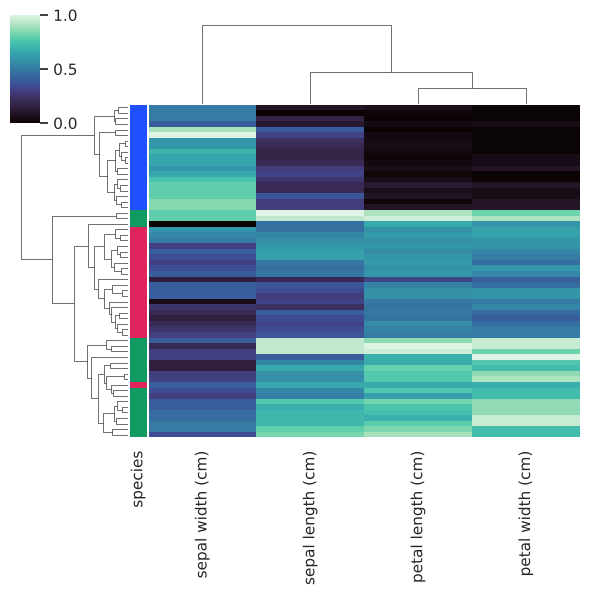

In [14]:
sub = iris.sample(60, random_state=1)
lut = dict(zip(sub["species"].unique(), ["#1f4fff", "#e0245e", "#0f9b62"]))
g = sns.clustermap(sub.drop(columns=["target", "species"]), standard_scale=1,
                   row_colors=sub["species"].map(lut), cmap="mako", figsize=(6, 6),
                   yticklabels=False)
plt.show()

## 16.7 Multi-variable plots · *Intermediate*

### 16.7.1 pairplot and jointplot

**pairplot**

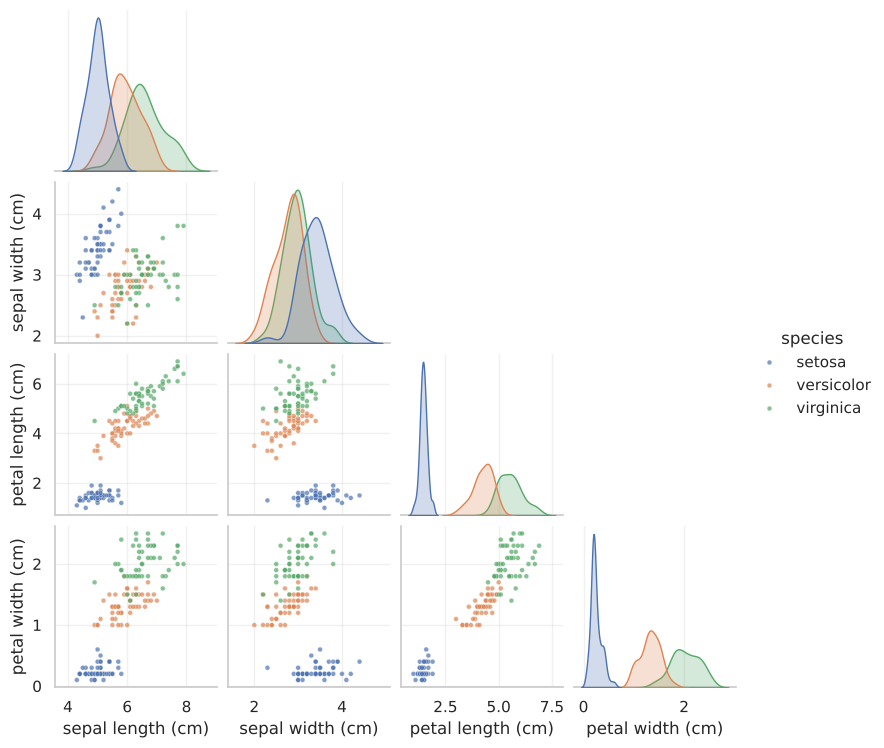

In [15]:
g = sns.pairplot(iris.drop(columns="target"), hue="species", corner=True, height=1.9,
                 plot_kws={"s": 12, "alpha": 0.7})
plt.show()

**jointplot with three kinds**

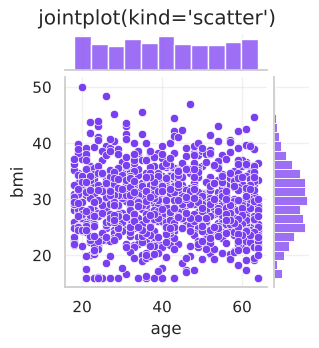

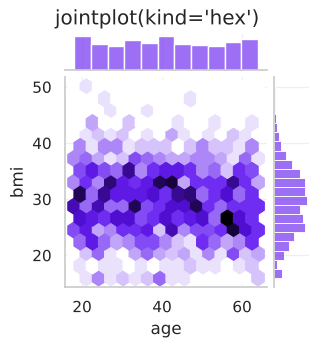

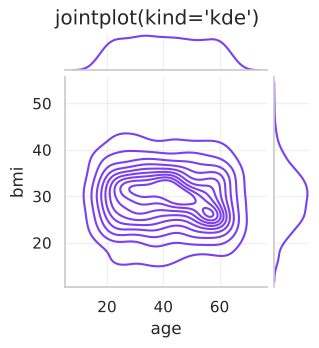

In [16]:
for kind in ["scatter", "hex", "kde"]:
    g = sns.jointplot(data=ins, x="age", y="bmi", kind=kind, height=3.4,
                      color="#7b3ff2")
    g.figure.suptitle(f"jointplot(kind='{kind}')", y=1.02)
plt.show()

## 16.8 Styling Seaborn · *Intermediate*

**Themes, contexts and palettes**

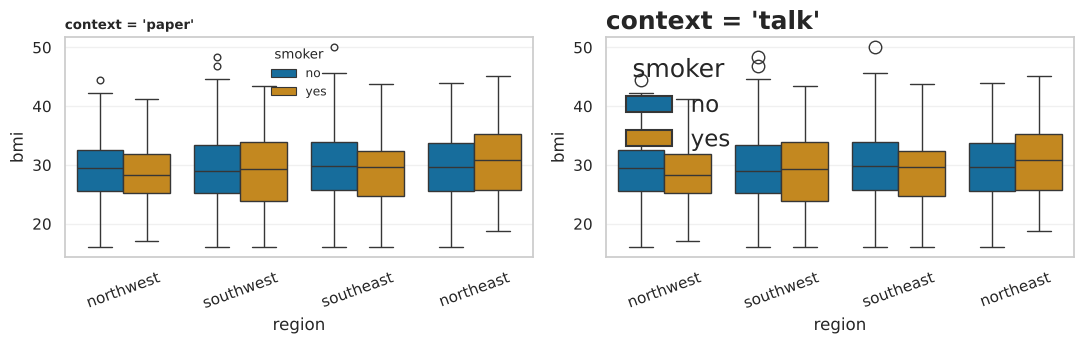

['#0173b2', '#de8f05', '#029e73', '#d55e00']


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, ctx in zip(axes, ["paper", "talk"]):
    with sns.plotting_context(ctx):
        sns.boxplot(data=ins, x="region", y="bmi", hue="smoker", palette="colorblind", ax=ax)
        ax.set_title(f"context = '{ctx}'")
        ax.tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()
print(sns.color_palette("colorblind").as_hex()[:4])

## 16.9 Saving Seaborn figures · *Beginner*

**Saving both kinds**

In [18]:
fig, ax = plt.subplots(figsize=(4, 3))
sns.histplot(data=ins, x="bmi", ax=ax)
fig.savefig("bmi_hist.png", dpi=300, bbox_inches="tight")
plt.close(fig)
g = sns.relplot(data=ins, x="age", y="charges", hue="smoker", height=3)
g.savefig("age_charges.pdf")
plt.close(g.figure)
print("saved bmi_hist.png and age_charges.pdf")

saved bmi_hist.png and age_charges.pdf


## Try it yourself

1. Use `catplot(kind="violin")` to show `charges` by `children`, split into columns by `smoker`.
2. Make a `jointplot` of `bmi` vs `charges` with `kind="reg"`. What does the fitted line suggest?
3. Draw a `clustermap` of the insurance numeric columns (scaled) for 80 random customers, with smokers marked in the row colours.

Worked solutions: [solutions-parts-1-4.ipynb](../../solutions/solutions-parts-1-4.ipynb), section *Chapter 16*.